Tugas Machine Learning 9

9.1 Persiapan Library

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, \
    GradientBoostingClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score

9.2 Import Dataset

In [ ]:
data = load_wine(as_frame=True)
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(X, y,
    test_size=0.2, random_state=42, stratify=y)

9.3 Preprocessing dan Training Model

In [ ]:
rf = RandomForestClassifier(n_estimators=300,
    oob_score=True, random_state=42)
rf.fit(X_train, y_train)

ada = AdaBoostClassifier(n_estimators=100, random_state=42)
ada.fit(X_train, y_train)

gb = GradientBoostingClassifier(n_estimators=100,
    learning_rate=0.1, random_state=42)
gb.fit(X_train, y_train)

tree_tunggal = DecisionTreeClassifier(random_state=42).fit(
    X_train,
    y_train)

9.4 Evaluasi

In [ ]:
print("OOB Score Random Forest:", round(rf.oob_score_, 3))

for nama, model in [("Decision Tree Tunggal", tree_tunggal),
    ("Random Forest", rf), ("AdaBoost", ada),
    ("Gradient Boosting", gb)]:
    acc = accuracy_score(y_test, model.predict(X_test))
    print(f"{nama}: Akurasi Test = {acc:.3f}")

OOB Score Random Forest: 0.979
Decision Tree Tunggal: Akurasi Test = 0.944
Random Forest: Akurasi Test = 1.000
AdaBoost: Akurasi Test = 0.917
Gradient Boosting: Akurasi Test = 0.944


9.5 Visualisasi

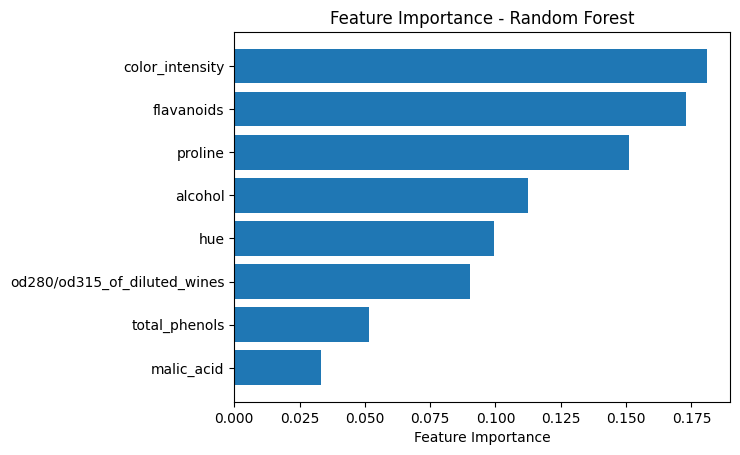

In [ ]:
importances = rf.feature_importances_
idx = np.argsort(importances)[::-1][:8]
plt.barh([data.feature_names[i] for i in idx][::-1],
    importances[idx][::-1])
plt.xlabel("Feature Importance")
plt.title("Feature Importance - Random Forest")
plt.show()

9.6 Praktikum 1

n_estimators=10: OOB=0.951, Test Acc=1.000
n_estimators=50: OOB=0.972, Test Acc=1.000
n_estimators=100: OOB=0.979, Test Acc=1.000
n_estimators=300: OOB=0.979, Test Acc=1.000
n_estimators=500: OOB=0.979, Test Acc=1.000


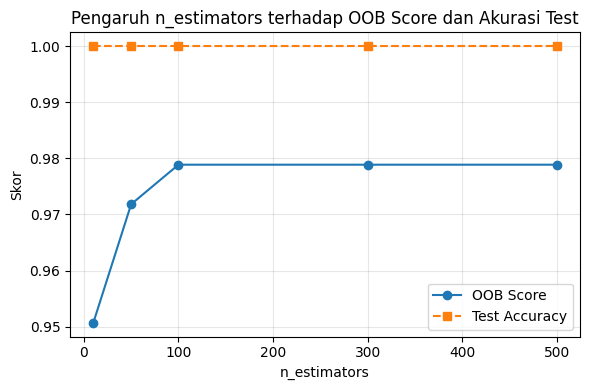

In [ ]:
daftar_n = [10, 50, 100, 300, 500]
oob_list, acc_list = [], []
for n in daftar_n:
    model = RandomForestClassifier(n_estimators=n,
        oob_score=True, random_state=42)
    model.fit(X_train, y_train)
    acc_test = accuracy_score(y_test, model.predict(X_test))
    print(f"n_estimators={n}: OOB={model.oob_score_:.3f}, "
        f"Test Acc={acc_test:.3f}")
    oob_list.append(model.oob_score_)
    acc_list.append(acc_test)

plt.figure(figsize=(6, 4))
plt.plot(daftar_n, oob_list, "o-", label="OOB Score")
plt.plot(daftar_n, acc_list, "s--", label="Test Accuracy")
plt.xlabel("n_estimators")
plt.ylabel("Skor")
plt.title("Pengaruh n_estimators terhadap OOB Score dan Akurasi Test")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

9.6 Praktikum 2

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

empat_model = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300,
                                            random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.1, random_state=42),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
baris = []
for nama, model in empat_model.items():
    skor = cross_val_score(model, X, y, cv=skf, scoring="f1_macro")
    baris.append({"Model": nama,
                  "Fold 1": skor[0], "Fold 2": skor[1],
                  "Fold 3": skor[2], "Fold 4": skor[3],
                  "Fold 5": skor[4],
                  "Rata-rata F1-macro": skor.mean(),
                  "Std": skor.std()})

tabel = pd.DataFrame(baris).set_index("Model").round(3)
print("\n=== Praktikum 2: Perbandingan Empat Model (Stratified 5-Fold, "
      "f1_macro) ===")
print(tabel.to_string())

terbaik = tabel["Rata-rata F1-macro"].idxmax()
stabil = tabel["Std"].idxmin()
print(f"\nModel terbaik (rata-rata F1-macro tertinggi): {terbaik} "
      f"({tabel.loc[terbaik, 'Rata-rata F1-macro']:.3f})")
print(f"Model paling stabil (std terkecil): {stabil} "
      f"({tabel.loc[stabil, 'Std']:.3f})")


=== Praktikum 2: Perbandingan Empat Model (Stratified 5-Fold, f1_macro) ===
                   Fold 1  Fold 2  Fold 3  Fold 4  Fold 5  Rata-rata F1-macro    Std
Model                                                                               
Decision Tree       0.893   0.915   0.890   0.836   0.946               0.896  0.036
Random Forest       0.972   1.000   1.000   0.948   1.000               0.984  0.021
AdaBoost            0.972   0.945   0.891   0.864   0.971               0.929  0.044
Gradient Boosting   0.918   0.890   0.946   0.895   0.970               0.924  0.030

Model terbaik (rata-rata F1-macro tertinggi): Random Forest (0.984)
Model paling stabil (std terkecil): Random Forest (0.021)


9.6 Praktikum

In [ ]:
for n in [10, 50, 100, 300, 500]:
    model = RandomForestClassifier(n_estimators=n,
        oob_score=True, random_state=42)
    model.fit(X_train, y_train)
    print(f"n_estimators={n}: OOB={model.oob_score_:.3f}, "
        f"Test Acc={accuracy_score(y_test, model.predict(X_test)):.3f}")

n_estimators=10: OOB=0.951, Test Acc=1.000
n_estimators=50: OOB=0.972, Test Acc=1.000
n_estimators=100: OOB=0.979, Test Acc=1.000
n_estimators=300: OOB=0.979, Test Acc=1.000
n_estimators=500: OOB=0.979, Test Acc=1.000
